# ANN 3: Keras Tuner + Class Imbalance
Keras Tuner searches for the best layers, units, dropout, L2, learning rate and batch size.

Main idea: only 11% of clients say "yes", so after tuning we compare two ways to handle this: class weights and focal loss.

# Import Libraries

In [ ]:
!pip install -q keras-tuner

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import keras_tuner as kt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

keras.utils.set_random_seed(42)
os.makedirs("weights/ANN3_Keras_Tuner", exist_ok=True)

# Load the Dataset

In [ ]:
from google.colab import files
files.upload()

In [4]:
df = pd.read_csv("bank_clean.csv")
df = df.rename(columns={"pdays_recorded": "previously_contacted"})   # same name as in ANN 2
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


In [5]:
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]
num_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx",
            "cons.conf.idx", "euribor3m", "nr.employed", "previously_contacted"]

# Train / Validation / Test Split

In [6]:
train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df["y"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["y"], random_state=42)

y_train = train_df["y"].values
y_val = val_df["y"].values
y_test = test_df["y"].values

print(len(train_df), len(val_df), len(test_df))

28823 6176 6177


# Prepare the Inputs

 One-hot encoding categorical columns and scaling numeric columns

In [7]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(train_df[cat_cols])

scaler = StandardScaler()
scaler.fit(train_df[num_cols])

def make_inputs(data):
    cat = encoder.transform(data[cat_cols])
    num = scaler.transform(data[num_cols])
    return np.hstack([num, cat])

x_train = make_inputs(train_df)
x_val = make_inputs(val_df)
x_test = make_inputs(test_df)

n_features = x_train.shape[1]
x_train.shape

(28823, 63)

In [8]:
# we give the "yes" class a bigger weight
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
class_weight = {0: len(y_train) / (2 * neg), 1: len(y_train) / (2 * pos)}
class_weight

{0: np.float64(0.563477478886456), 1: np.float64(4.438404681244226)}

Accuracy alone is misleading, so we also look at AUC and recall.

# Baseline Model

In [9]:
def build_baseline_model():
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(curve="PR", name="auc"), keras.metrics.Recall(name="recall")]
    )
    return model

baseline_model = build_baseline_model()
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,209 (24.25 KB)

 Trainable params: 6,209 (24.25 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = baseline_model.fit(x_train, y_train, epochs=20, batch_size=256,
                             validation_data=(x_val, y_val), class_weight=class_weight)
baseline_model.save_weights("weights/ANN3_Keras_Tuner/baseline.weights.h5")

Epoch 1/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7669 - auc: 0.4007 - loss: 0.5654 - recall: 0.6495 - val_accuracy: 0.8159 - val_auc: 0.4340 - val_loss: 0.5177 - val_recall: 0.6537
Epoch 2/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8195 - auc: 0.4428 - loss: 0.5398 - recall: 0.6307 - val_accuracy: 0.8191 - val_auc: 0.4414 - val_loss: 0.5167 - val_recall: 0.6466
Epoch 3/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8240 - auc: 0.4533 - loss: 0.5347 - recall: 0.6286 - val_accuracy: 0.8225 - val_auc: 0.4446 - val_loss: 0.5141 - val_recall: 0.6437
Epoch 4/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8260 - auc: 0.4591 - loss: 0.5311 - recall: 0.6320 - val_accuracy: 0.8248 - val_auc: 0.4471 - val_loss: 0.5137 - val_recall: 0.6480
Epoch 5/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8280 - auc: 0.4632 - loss: 0.5283 - recall: 0.6335 - val_accuracy: 0.8271 - val_auc: 0.4480 - val_loss: 0.5116 - val_recall: 0.6480
Epoch 6/20

In [11]:
loss, acc, auc, recall = baseline_model.evaluate(x_val, y_val, verbose=0)
print(f"Baseline → accuracy={acc:.4f}  AUC={auc:.4f}  recall={recall:.4f}")

Baseline → accuracy=0.8004  AUC=0.4429  recall=0.6624


# Keras Tuner (Bayesian Optimization)

Bayesian Optimization learns from the trials it already ran and picks better values for the next trial.

In [12]:
class TunedANN(kt.HyperModel):

    def build(self, hp):
        l2 = hp.Float("l2", 1e-5, 1e-2, sampling="log")
        rate = hp.Float("dropout", 0.0, 0.5, step=0.1)
        lr = hp.Float("learning_rate", 1e-4, 1e-2, sampling="log")

        model = keras.Sequential()
        model.add(keras.Input(shape=(n_features,)))
        for i in range(hp.Int("layers", 1, 3)):
            model.add(layers.Dense(hp.Int(f"units_{i}", 16, 256, step=16), activation="relu",
                                   kernel_regularizer=regularizers.l2(l2)))
            model.add(layers.Dropout(rate))
        model.add(layers.Dense(1, activation="sigmoid"))

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=lr),
            loss="binary_crossentropy",
            metrics=["accuracy", keras.metrics.AUC(curve="PR", name="auc"), keras.metrics.Recall(name="recall")]
        )
        return model

    def fit(self, hp, model, *args, **kwargs):
        # batch size is tuned here
        return model.fit(*args, batch_size=hp.Choice("batch_size", [64, 128, 256, 512]), **kwargs)

In [13]:
tuner = kt.BayesianOptimization(
    TunedANN(),
    objective=kt.Objective("val_auc", direction="max"),
    max_trials=25,
    seed=42,
    directory="tuner",
    project_name="ann3",
    overwrite=True
)
tuner.search_space_summary()

Search space summary
Default search space size: 5
l2 (Float)
{'default': 1e-05, 'conditions': [], 'min_value': 1e-05, 'max_value': 0.01, 'step': None, 'sampling': 'log'}
dropout (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}
layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 16, 'max_value': 256, 'step': 16, 'sampling': 'linear'}


In [14]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True)

tuner.search(x_train, y_train, epochs=40, validation_data=(x_val, y_val),
             class_weight=class_weight, callbacks=[early_stop])

Trial 25 Complete [00h 00m 08s]
val_auc: 0.458301842212677
Best val_auc So Far: 0.46366462111473083
Total elapsed time: 00h 06m 26s


# Best Hyperparameters

In [15]:
best_hp = tuner.get_best_hyperparameters(1)[0]
best_hp.values

{'l2': 0.0002906286580403997,
 'dropout': 0.30000000000000004,
 'learning_rate': 0.0023361709154431664,
 'layers': 2,
 'units_0': 32,
 'batch_size': 256,
 'units_1': 16,
 'units_2': 144}

In [16]:
# top 5 trials
rows = []
for trial in tuner.oracle.get_best_trials(5):
    row = trial.hyperparameters.values.copy()
    row["val_auc"] = round(trial.score, 4)
    rows.append(row)

pd.DataFrame(rows)

,l2,dropout,learning_rate,layers,units_0,batch_size,units_1,units_2,val_auc
0,0.000291,0.3,0.002336,2,32,256,16,144,0.4637
1,0.000027,0.2,0.000802,1,80,512,96,96,0.4629
2,0.002064,0.2,0.001463,3,128,512,48,160,0.4610
3,0.000173,0.2,0.000929,3,160,64,64,16,0.4608
4,0.000129,0.3,0.004256,1,80,256,48,128,0.4602


Only the units of the first `layers` layers are used, the other units columns can be ignored.

# Class Weights vs Focal Loss

- Class weights: normal loss, but each "yes" counts more.
- Focal loss: no class weights, the loss focuses on the hard examples instead.

In [17]:
def build_best_model(loss):
    model = tuner.hypermodel.build(best_hp)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=best_hp.get("learning_rate")),
        loss=loss,
        metrics=["accuracy", keras.metrics.AUC(curve="PR", name="auc"), keras.metrics.Recall(name="recall")]
    )
    return model

best_batch = best_hp.get("batch_size")

### Class Weights

In [18]:
cw_model = build_best_model("binary_crossentropy")

early_stop_cw = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8, restore_best_weights=True)

history_cw = cw_model.fit(x_train, y_train, epochs=100, batch_size=best_batch,
                          validation_data=(x_val, y_val), class_weight=class_weight,
                          callbacks=[early_stop_cw])
cw_model.save_weights("weights/ANN3_Keras_Tuner/class_weights.weights.h5")

Epoch 1/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6935 - auc: 0.3202 - loss: 0.6386 - recall: 0.6196 - val_accuracy: 0.7652 - val_auc: 0.4296 - val_loss: 0.5798 - val_recall: 0.6882
Epoch 2/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7879 - auc: 0.3925 - loss: 0.5869 - recall: 0.6314 - val_accuracy: 0.8075 - val_auc: 0.4399 - val_loss: 0.5631 - val_recall: 0.6451
Epoch 3/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8139 - auc: 0.4037 - loss: 0.5752 - recall: 0.6267 - val_accuracy: 0.8314 - val_auc: 0.4447 - val_loss: 0.5545 - val_recall: 0.6236
Epoch 4/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8256 - auc: 0.4195 - loss: 0.5671 - recall: 0.6116 - val_accuracy: 0.8293 - val_auc: 0.4477 - val_loss: 0.5424 - val_recall: 0.6221
Epoch 5/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8256 - auc: 0.4227 - loss: 0.5633 - recall: 0.6193 - val_accuracy: 0.8274 - val_auc: 0.4522 - val_loss: 0.5444 - val_recall: 0.6264
Epoch

### Focal Loss

In [19]:
focal_loss = keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.75, gamma=2.0)
focal_model = build_best_model(focal_loss)

early_stop_focal = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8, restore_best_weights=True)

history_focal = focal_model.fit(x_train, y_train, epochs=100, batch_size=best_batch,
                                validation_data=(x_val, y_val),
                                callbacks=[early_stop_focal])
focal_model.save_weights("weights/ANN3_Keras_Tuner/focal_loss.weights.h5")

Epoch 1/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8593 - auc: 0.3131 - loss: 0.0536 - recall: 0.3120 - val_accuracy: 0.8805 - val_auc: 0.4326 - val_loss: 0.0449 - val_recall: 0.3922
Epoch 2/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8804 - auc: 0.3867 - loss: 0.0443 - recall: 0.3948 - val_accuracy: 0.8744 - val_auc: 0.4446 - val_loss: 0.0406 - val_recall: 0.4770
Epoch 3/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8782 - auc: 0.4059 - loss: 0.0410 - recall: 0.4272 - val_accuracy: 0.8776 - val_auc: 0.4469 - val_loss: 0.0391 - val_recall: 0.4871
Epoch 4/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8770 - auc: 0.4057 - loss: 0.0396 - recall: 0.4472 - val_accuracy: 0.8782 - val_auc: 0.4485 - val_loss: 0.0380 - val_recall: 0.4928
Epoch 5/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8765 - auc: 0.4072 - loss: 0.0389 - recall: 0.4666 - val_accuracy: 0.8729 - val_auc: 0.4484 - val_loss: 0.0375 - val_recall: 0.5244
Epoch

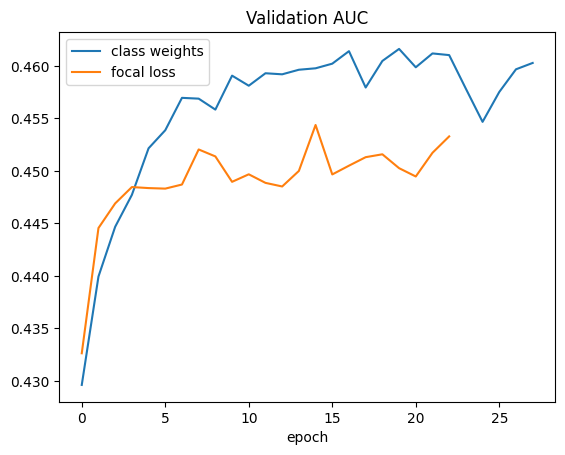

In [20]:
plt.plot(history_cw.history["val_auc"], label="class weights")
plt.plot(history_focal.history["val_auc"], label="focal loss")
plt.title("Validation AUC")
plt.xlabel("epoch")
plt.legend()
plt.show()

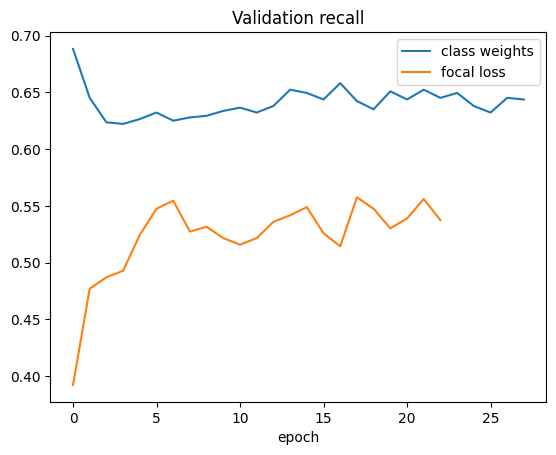

In [21]:
plt.plot(history_cw.history["val_recall"], label="class weights")
plt.plot(history_focal.history["val_recall"], label="focal loss")
plt.title("Validation recall")
plt.xlabel("epoch")
plt.legend()
plt.show()

We compare AUC and recall, not loss, because the two losses are on different scales.

# Evaluate on the Test Set

In [22]:
for name, model in [("Baseline", baseline_model), ("Class weights", cw_model), ("Focal loss", focal_model)]:
    loss, acc, auc, recall = model.evaluate(x_test, y_test, verbose=0)
    print(f"{name} → accuracy={acc:.4f}  AUC={auc:.4f}  recall={recall:.4f}")

Baseline → accuracy=0.8129  AUC=0.4705  recall=0.6595
Class weights → accuracy=0.8462  AUC=0.4806  recall=0.6638
Focal loss → accuracy=0.8784  AUC=0.4653  recall=0.5647


Class weights
              precision    recall  f1-score   support
          no       0.95      0.87      0.91      5481
         yes       0.39      0.66      0.49       696
    accuracy                           0.85      6177
   macro avg       0.67      0.77      0.70      6177
weighted avg       0.89      0.85      0.86      6177


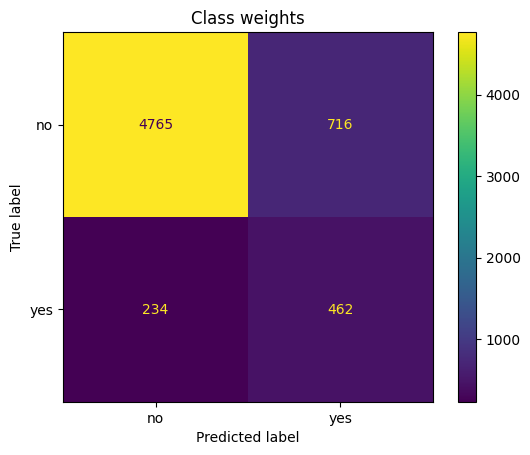

Focal loss
              precision    recall  f1-score   support
          no       0.94      0.92      0.93      5481
         yes       0.47      0.56      0.51       696
    accuracy                           0.88      6177
   macro avg       0.71      0.74      0.72      6177
weighted avg       0.89      0.88      0.88      6177


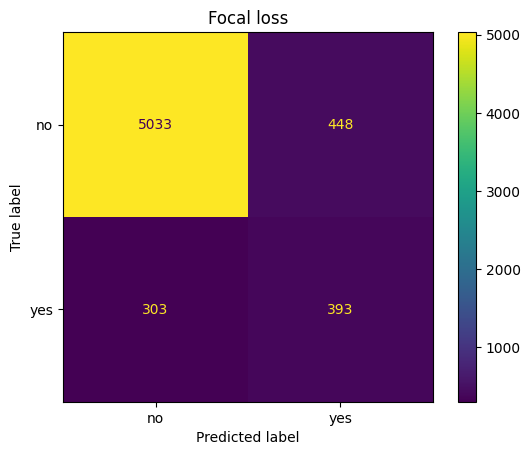

In [23]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

for name, model in [("Class weights", cw_model), ("Focal loss", focal_model)]:
    y_pred = (model.predict(x_test, verbose=0) > 0.5).astype(int)
    print(name)
    print(classification_report(y_test, y_pred, target_names=["no", "yes"]))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["no", "yes"])
    plt.title(name)
    plt.show()

# Save the Final Model

We keep the model with the higher validation AUC.

In [24]:
cw_val_auc = cw_model.evaluate(x_val, y_val, verbose=0)[2]
focal_val_auc = focal_model.evaluate(x_val, y_val, verbose=0)[2]

if cw_val_auc >= focal_val_auc:
    final_model = cw_model
    print("Final model: class weights")
else:
    final_model = focal_model
    print("Final model: focal loss")

Final model: class weights


In [25]:
final_model.save_weights("weights/ANN3_Keras_Tuner/final.weights.h5")
final_model.save("weights/ANN3_Keras_Tuner/final_model.keras")
os.listdir("weights/ANN3_Keras_Tuner")

['baseline.weights.h5',
 'class_weights.weights.h5',
 'final.weights.h5',
 'final_model.keras',
 'focal_loss.weights.h5']

# Load the Model and Predict

In [26]:
loaded_model = tuner.hypermodel.build(best_hp)
loaded_model.load_weights("weights/ANN3_Keras_Tuner/final.weights.h5")

# predict the first 5 clients of the test set
new_clients = test_df.head(5)
probs = loaded_model.predict(make_inputs(new_clients), verbose=0).ravel()

pd.DataFrame({
    "job": new_clients["job"].values,
    "age": new_clients["age"].values,
    "probability": probs.round(3),
    "prediction": np.where(probs > 0.5, "yes", "no"),
    "actual": np.where(new_clients["y"] == 1, "yes", "no")
})

,job,age,probability,prediction,actual
0,technician,36,0.210,no,no
1,technician,38,0.399,no,no
2,retired,58,0.239,no,no
3,admin.,32,0.329,no,no
4,admin.,36,0.262,no,no


# Insights
- Best hyperparameters: 2 hidden layers (32 and 16 units), dropout 0.3, L2 0.0003, learning rate 0.0023, batch size 256. A small network was enough, bigger ones did not do better.
- Tuned model vs baseline: validation AUC went from 0.443 to 0.464. The baseline started to overfit after about 10 epochs, dropout, L2 and early stopping fixed that.
- Class weights vs focal loss: class weights had the higher AUC (0.481 vs 0.465) and found more of the "yes" clients (recall 66% vs 56%). Focal loss made fewer wrong calls (precision 47% vs 39%) and had higher accuracy (88% vs 85%).
- Final model: class weights, because it had the higher validation AUC (0.462 vs 0.454).
- Test set: accuracy 85%, AUC 0.481, recall 66%. The model found 462 of the 696 clients who subscribed.